# Assignment 8 — Pre-trained BERT for Text Classification

**Objective:** Implement a pre-trained BERT model for multiclass text classification using the **AG News** dataset.

This is a standalone assignment and does not depend on previous assignments.

### Dataset
AG News contains four news categories:
- World
- Sports
- Business
- Sci/Tech

### Workflow
1. Load and explore AG News
2. Tokenize text using BERT tokenizer
3. Fine-tune `bert-base-uncased`
4. Evaluate with accuracy, precision, recall and F1-score
5. Plot a confusion matrix
6. Test custom text
7. Save and reload the fine-tuned model


## 1. Install Required Libraries

In [1]:
%pip install -q transformers datasets accelerate scikit-learn matplotlib seaborn pandas


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## 2. Import Libraries and Check Hardware

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from transformers import TrainingArguments, Trainer

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.14.0+cpu
Device: cpu


## 3. Load the AG News Dataset

In [4]:
dataset = load_dataset("fancyzhx/ag_news")

print(dataset)
print("Training samples:", len(dataset["train"]))
print("Testing samples:", len(dataset["test"]))

d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\manth\.cache\huggingface\hub\datasets--fancyzhx--ag_news. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\huggingface_hu

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
Training samples: 120000
Testing samples: 7600


## 4. Explore the Dataset

{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}

Class names: ['World', 'Sports', 'Business', 'Sci/Tech']


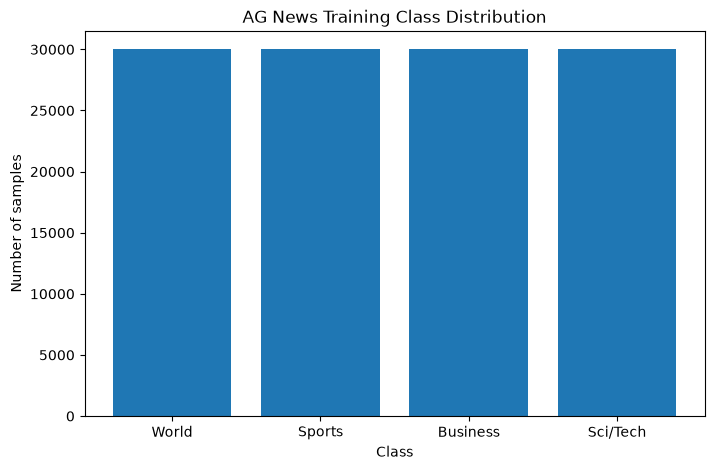

In [ ]:
class_names = ["World", "Sports", "Business", "Sci/Tech"]

print(dataset["train"][0])
print("\nClass names:", class_names)

counts = pd.Series(dataset["train"]["label"]).value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(class_names, counts.values)
plt.xlabel("Class")
plt.ylabel("Number of samples")
plt.title("AG News Training Class Distribution")
plt.show()

## 5. Display Sample Articles

In [6]:
for i in range(5):
    print(f"\nSample {i + 1}")
    print("Category:", class_names[dataset["train"][i]["label"]])
    print("Text:", dataset["train"][i]["text"])



Sample 1
Category: Business
Text: Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.

Sample 2
Category: Business
Text: Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputation for making well-timed and occasionally\controversial plays in the defense industry, has quietly placed\its bets on another part of the market.

Sample 3
Category: Business
Text: Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the outlook for earnings are expected to\hang over the stock market next week during the depth of the\summer doldrums.

Sample 4
Category: Business
Text: Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the main pipeline in southern Iraq after\intelligence showed a rebel militia could strike\infrastr

## 6. Optional Fast-Run Mode

Fine-tuning BERT on the complete dataset can take substantial time. For a lab demonstration, keep `USE_SUBSET = True`. Set it to `False` to use the complete AG News dataset.

In [7]:
USE_SUBSET = True

TRAIN_SAMPLES = 8000
TEST_SAMPLES = 2000

if USE_SUBSET:
    dataset["train"] = dataset["train"].shuffle(seed=42).select(range(TRAIN_SAMPLES))
    dataset["test"] = dataset["test"].shuffle(seed=42).select(range(TEST_SAMPLES))

print("Training samples used:", len(dataset["train"]))
print("Testing samples used:", len(dataset["test"]))


Training samples used: 8000
Testing samples used: 2000


## 7. Load the Pre-trained BERT Tokenizer

In [8]:
MODEL_NAME = "bert-base-uncased"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print("Tokenizer loaded.")
print("Vocabulary size:", tokenizer.vocab_size)


d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\manth\.cache\huggingface\hub\models--bert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


Tokenizer loaded.
Vocabulary size: 30522


## 8. Tokenize the Text

In [9]:
def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        padding="max_length",
        truncation=True,
        max_length=128
    )

tokenized_dataset = dataset.map(
    tokenize_function,
    batched=True
)

print(tokenized_dataset)


Map: 100%|██████████| 2000/2000 [00:00<00:00, 18109.89 examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 8000
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
        num_rows: 2000
    })
})


## 9. Prepare Dataset for PyTorch

In [10]:
tokenized_dataset = tokenized_dataset.rename_column("label", "labels")

tokenized_dataset.set_format(
    "torch",
    columns=["input_ids", "attention_mask", "labels"]
)

print(tokenized_dataset["train"][0].keys())


dict_keys(['labels', 'input_ids', 'attention_mask'])


## 10. Load Pre-trained BERT for Classification

In [11]:
id2label = {
    0: "World",
    1: "Sports",
    2: "Business",
    3: "Sci/Tech"
}

label2id = {v: k for k, v in id2label.items()}

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=4,
    id2label=id2label,
    label2id=label2id
)

print("BERT classification model loaded.")


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1207.90it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
classifier.bias                            | MISSING    | 
classifier.weight                          | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

BERT classification model loaded.


## 11. Define Evaluation Metrics

In [12]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)

    accuracy = accuracy_score(labels, predictions)

    precision, recall, f1, _ = precision_recall_fscore_support(
        labels,
        predictions,
        average="weighted",
        zero_division=0
    )

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }


## 12. Configure BERT Fine-tuning

In [13]:
training_args = TrainingArguments(
    output_dir="./bert_agnews_results",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=2,
    weight_decay=0.01,
    logging_steps=100,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    report_to="none"
)

print("Training configuration ready.")


Training configuration ready.


## 13. Create the Trainer

In [14]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["test"],
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)

print("Trainer created.")


Trainer created.


## 14. Fine-tune BERT

In [15]:
training_result = trainer.train()

print("BERT fine-tuning completed.")


d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,Precision,Recall,F1
1,0.296351,0.307157,0.910500,0.912336,0.910500,0.910303
2,0.186035,0.300636,0.912500,0.914082,0.912500,0.912395


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.15it/s]
d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  6.00it/s]
[transformers] There were missing keys in the checkpoint model loaded: ['bert.embeddings.LayerNorm.weight', 'bert.embeddings.LayerNorm.bias', 'bert.encoder.layer.0.attention.output.LayerNorm.weight', 'bert.encoder.layer.0.attention.output.LayerNorm.bias', 'bert.encoder.layer.0.output.LayerNorm.weight', 'bert.encoder.layer.0.output.LayerNorm.bias', 'bert.encoder.layer.1.attention.output.LayerNorm.weight', 'bert.encoder.layer.1.attention.output.LayerNorm.bias', 'bert.encoder.layer.1.output.LayerNorm.weight', 'bert.encoder.layer.1.output.LayerNorm.bias', 'bert.encoder.layer.2.attention.output.LayerNo

BERT fine-tuning completed.


## 15. Evaluate the Model

In [16]:
evaluation_results = trainer.evaluate()

print("\nEvaluation Results:")
for key, value in evaluation_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")


d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision,Recall,F1
0.186035,0.300636,2,0.912500,0.914082,0.912500,0.912395



Evaluation Results:
eval_loss: 0.3006
eval_accuracy: 0.9125
eval_precision: 0.9141
eval_recall: 0.9125
eval_f1: 0.9124


## 16. Generate Predictions

In [17]:
prediction_output = trainer.predict(tokenized_dataset["test"])

predicted_labels = np.argmax(
    prediction_output.predictions,
    axis=-1
)

actual_labels = prediction_output.label_ids

print("Predictions generated.")


d:\Manthan\Vit Btech\Vit TY\Sem 5\Deep Learning\Lab\DL_Lab\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Predictions generated.


## 17. Classification Report

In [18]:
print(
    classification_report(
        actual_labels,
        predicted_labels,
        target_names=class_names,
        zero_division=0
    )
)


              precision    recall  f1-score   support

       World       0.94      0.90      0.92       497
      Sports       0.97      0.98      0.98       483
    Business       0.91      0.84      0.88       522
    Sci/Tech       0.84      0.93      0.88       498

    accuracy                           0.91      2000
   macro avg       0.91      0.91      0.91      2000
weighted avg       0.91      0.91      0.91      2000



## 18. Confusion Matrix

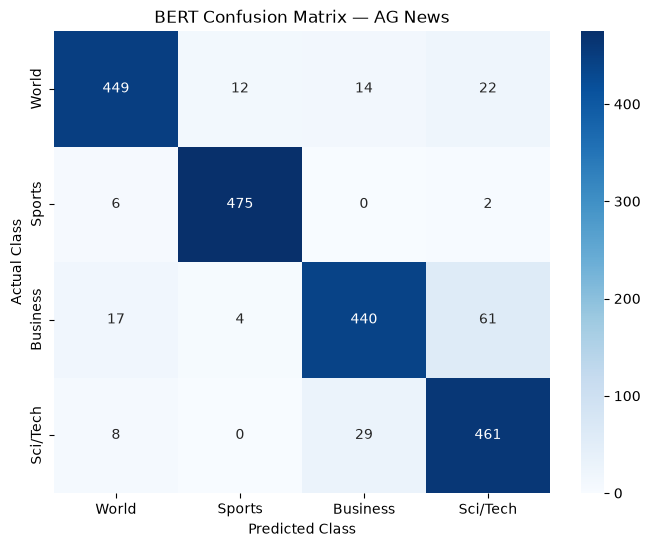

In [19]:
cm = confusion_matrix(actual_labels, predicted_labels)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("BERT Confusion Matrix — AG News")
plt.show()


## 19. Evaluation Metrics Visualization

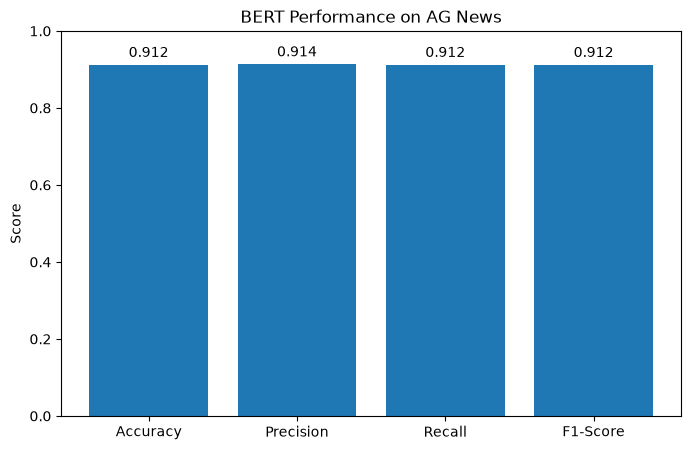

In [20]:
metric_names = ["Accuracy", "Precision", "Recall", "F1-Score"]

metric_values = [
    evaluation_results["eval_accuracy"],
    evaluation_results["eval_precision"],
    evaluation_results["eval_recall"],
    evaluation_results["eval_f1"]
]

plt.figure(figsize=(8, 5))
bars = plt.bar(metric_names, metric_values)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("BERT Performance on AG News")

for bar, value in zip(bars, metric_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.02,
        f"{value:.3f}",
        ha="center"
    )

plt.show()


## 20. Test BERT on Custom News Text

In [21]:
def predict_news(text):
    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding=True,
        max_length=128
    )

    inputs = {key: value.to(model.device) for key, value in inputs.items()}

    with torch.no_grad():
        outputs = model(**inputs)

    probabilities = torch.softmax(outputs.logits, dim=-1)

    predicted_class = torch.argmax(
        probabilities,
        dim=-1
    ).item()

    confidence = probabilities[0][predicted_class].item()

    return class_names[predicted_class], confidence


sample_texts = [
    "The football team won the championship after a dramatic final match.",
    "The company reported strong quarterly earnings and increased revenue.",
    "Scientists developed a new technology that improves computer performance.",
    "World leaders met to discuss international relations and global security."
]

for text in sample_texts:
    prediction, confidence = predict_news(text)

    print("\nText:", text)
    print("Predicted category:", prediction)
    print("Confidence:", f"{confidence * 100:.2f}%")



Text: The football team won the championship after a dramatic final match.
Predicted category: Sports
Confidence: 97.54%

Text: The company reported strong quarterly earnings and increased revenue.
Predicted category: Business
Confidence: 95.87%

Text: Scientists developed a new technology that improves computer performance.
Predicted category: Sci/Tech
Confidence: 98.60%

Text: World leaders met to discuss international relations and global security.
Predicted category: World
Confidence: 98.63%


## 21. Save the Fine-tuned Model

In [22]:
SAVE_PATH = "./bert_agnews_model"

trainer.save_model(SAVE_PATH)
tokenizer.save_pretrained(SAVE_PATH)

print("Model saved successfully at:", SAVE_PATH)


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  5.93it/s]


Model saved successfully at: ./bert_agnews_model


## 22. Reload the Saved Model

In [23]:
loaded_tokenizer = AutoTokenizer.from_pretrained(SAVE_PATH)

loaded_model = AutoModelForSequenceClassification.from_pretrained(
    SAVE_PATH
)

loaded_model.to(device)

print("Saved BERT model loaded successfully.")


Loading weights: 100%|██████████| 201/201 [00:00<00:00, 857.79it/s]

Saved BERT model loaded successfully.


## 23. Conclusion

This experiment implements transfer learning using a pre-trained **BERT** model for multiclass text classification.

The model is fine-tuned on the **AG News** dataset and evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix